# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Habrian Daffa Dwiyandana
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** xxx
- **Pertanyaan 2:** xxx
- ...

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi agar rapi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Data Wrangling

### Gathering Data

#### Load df ...

In [3]:
day_df = pd.read_csv ("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Preview day_df:")
display(day_df.head())

print("Preview hour_df:")
display(hour_df.head())

Preview day_df:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Preview hour_df:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset terdiri dari dua tabel utama, yaitu day_df (731 baris, 16 kolom) yang merekam agregasi penyewaan harian, dan hour_df (17379 baris, 17 kolom) yang merekam transaksi secara rinci per jam (hr).
- Kedua tabel mencakup data operasional dari 1 januari 2011 hingga 31 Desember 2012 beserta atribut kalender dan kondisi cuaca

### Assessing Data

#### Identifying ... problem

In [4]:
print ("=== info day_df ===")
display(day_df.info())

print ("=== info hour_df ===")
display(hour_df.info())

print("\nMissing values day_df:", day_df.isnull().sum().sum())
print("Missing values hour_df:", hour_df.isnull().sum().sum())
print("Duplikasi day_df:", day_df.duplicated().sum())
print("Duplikasi hour_df:", hour_df.duplicated().sum())

print("n=== statistik deskriptif day_df ===")
display(day_df.describe())

print("n=== statistik deskriptif hour_df ===")
display(hour_df.describe())

print("njumlah baris hum == 0 di day_df: ", (day_df["hum"] == 0). sum())
print("jumlah baris hum == 0 pada hour_df: ", (hour_df["hum"] == 0).sum())
display(day_df[day_df["hum"] == 0][["instant", "dteday", "season", "weathersit", "temp", "hum", "cnt"]])




=== info day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


None

=== info hour_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


None


Missing values day_df: 0
Missing values hour_df: 0
Duplikasi day_df: 0
Duplikasi hour_df: 0
n=== statistik deskriptif day_df ===


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


n=== statistik deskriptif hour_df ===


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


njumlah baris hum == 0 di day_df:  1
jumlah baris hum == 0 pada hour_df:  22


,instant,dteday,season,weathersit,temp,hum,cnt
68,69,2011-03-10,1,3,0.389091,0.0,623


**Steps to Take:**
- Mengubah tipe data kolom dteday dari object (string) menjadi datetime64 pada day_df dan hour_df
- Menangani inaccurate value pada kolom hum yang bernilai 0.0 (terjadi pada 10 Maret 2011 saat cuaca hujan/salju ringan) dengan menggantinya menjadi NaN lalu melakukan imputasi menggunakan nilai median kelembaban berdasarkan kombinasi season dan weathersit yang sama
- Membuat kolom label kategorikal (season_label, year, weather_label, weekday_label) serta kolom denormalisasi metrik cuaca (temp_c, atemp_c, hum_pct, windspeed_kmh) agar hasil eksplorasi dan visualisasi lebih mudah diinterpretasikan
- Mempertahankan outlier pada kolom jumlah penyewaan (casual, registered, cnt) karena mencerminkan lonjakan permintaan alami saat jam sibuk dan hari libur cerah

**Insight:** (Opsional)
- Tidak ditemukan missing value maupun duplicate data di kedua tabel
- Tipe Data Tidak Sesuai (Incorrect Data Type): Kolom dteday masih terbaca sebagai object, serta variabel kategorikal masih dikodekan dalam bentuk angka

### Cleaning Data

#### Fixing ... problem

In [6]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

for df in [day_df, hour_df]:
  df["hum"] = df["hum"].replace(0, np.nan)
  df["hum"] = df["hum"].fillna(df.groupby(["season", "weathersit"])["hum"].transform("median"))

season_map = {1: "Spring", 2:"Summer", 3: "Fall", 4: "Winter"}
yr_map = {0: 2011, 1: 2012}
weather_map = {
    1: "Cerah/Berawa Ringan",
    2: "Berkabut/Beawan",
    3: "Hujan/Salju Ringan",
    4: "Cuaca Ekstrem"
}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}

for df in [day_df, hour_df]:
  df["season_label"] = df["season"].map(season_map)
  df["year"] = df["yr"].map(yr_map)
  df["weather_label"] = df["weathersit"].map(weather_map)
  df["weekday_label"] = df["weekday"].map(weekday_map)
  df["temp_c"] = df["temp"] * 41
  df["atemp_c"] = df["atemp"] * 50
  df["hum_pct"] = df["hum"] * 100
  df["windspeed_kmh"] = df["windspeed"] * 67

print("Sisa hum == 0 pada day_df:", (day_df["hum"] == 0).sum())
print("Sisa hum == 0 pada hour_df:", (hour_df["hum"] == 0).sum())
print("Tipe data dteday hour_df:", hour_df["dteday"].dtype)

hour_df.to_csv("main_data.csv", index=False)


Sisa hum == 0 pada day_df: 0
Sisa hum == 0 pada hour_df: 0
Tipe data dteday hour_df: datetime64[ns]


**Insight:** (Opsional)
- Seluruh anomali kelembaban bernilai 0.0 berhasil diimputasi secara proporsional tanpa merusak distribusi data cuaca.


## Exploratory Data Analysis (EDA)

### Explore ...

In [7]:
season_summary = day_df.groupby(["year", "season_label"])[["casual", "registered", "cnt"]].agg(["mean", "sum"])
print("=== RANGKUMAN PENYEWAAN PER TAHUN & MUSIM ===")
display(season_summary)

q1_df = hour_df[
    (hour_df["workingday"] == 1) &
    (hour_df["hr"].isin([8, 17])) &
    (hour_df["season_label"] == "Fall")
]
q1_summary = q1_df.groupby(["year", "hr"])["cnt"].agg(["count", "mean", "median", "sum"]).reset_index()

for hr in [8, 17]:
    m_2011 = q1_summary[(q1_summary["year"] == 2011) & (q1_summary["hr"] == hr)]["mean"].values[0]
    m_2012 = q1_summary[(q1_summary["year"] == 2012) & (q1_summary["hr"] == hr)]["mean"].values[0]
    growth = ((m_2012 - m_2011) / m_2011) * 100
    print(f"Jam {hr:02d}:00 -> Rata-rata 2011: {m_2011:.2f} | Rata-rata 2012: {m_2012:.2f} | Kenaikan: +{growth:.2f}%")

display(q1_summary)

q2_df = hour_df[hour_df["workingday"] == 0][["temp_c", "hum_pct", "windspeed_kmh", "casual", "registered", "cnt"]]
q2_corr = q2_df.corr()
print("\n=== MATRIKS KORELASI CUACA VS PENYEWA (AKHIR PEKAN/LIBUR) ===")
display(q2_corr[["casual", "registered", "cnt"]])

=== RANGKUMAN PENYEWAAN PER TAHUN & MUSIM ===


casual           registered                  cnt  \
                          mean     sum         mean     sum         mean   
year season_label                                                          
2011 Fall          1015.425532   95450  3448.936170  324200  4464.361702   
     Spring         238.055556   21425  1428.611111  128575  1666.666667   
     Summer         843.086957   77564  2932.086957  269752  3775.173913   
     Winter         593.404494   52813  3071.056180  273324  3664.460674   
2012 Fall          1389.797872  130641  5434.446809  510838  6824.244681   
     Spring         430.736264   39197  3100.560440  282151  3531.296703   
     Summer        1369.108696  125958  4840.380435  445315  6209.489130   
     Winter         864.820225   76969  4927.044944  438507  5791.865169   

                           
                      sum  
year season_label          
2011 Fall          419650  
     Spring        150000  
     Summer        347316  
     Winter        326137  
2012 Fall          641479  
     Spring        321348  
     Summer        571273  
     Winter        515476

Jam 08:00 -> Rata-rata 2011: 420.11 | Rata-rata 2012: 679.38 | Kenaikan: +61.72%
Jam 17:00 -> Rata-rata 2011: 507.42 | Rata-rata 2012: 796.66 | Kenaikan: +57.00%


,year,hr,count,mean,median,sum
0,2011,8,66,420.106061,424.5,27727
1,2011,17,66,507.424242,541.0,33490
2,2012,8,65,679.384615,687.0,44160
3,2012,17,65,796.661538,833.0,51783



=== MATRIKS KORELASI CUACA VS PENYEWA (AKHIR PEKAN/LIBUR) ===


,casual,registered,cnt
temp_c,0.541886,0.466017,0.515392
hum_pct,-0.381183,-0.388505,-0.400388
windspeed_kmh,0.089751,0.109504,0.105515
casual,1.000000,0.848682,0.944055
registered,0.848682,1.000000,0.975628
cnt,0.944055,0.975628,1.000000


**Insight:** (Opsional)
- Pertanyaan 1: Pada hari kerja di musim gugur, rata-rata penyewaan sepeda pada jam 08:00 meningkat dari 420,11 unit/jam (2011) menjadi 679,38 unit/jam (2012) atau naik +61,72%. Sementara pada jam 17:00, rata-rata penyewaan meningkat dari 507,42 unit/jam (2011) menjadi 796,66 unit/jam (2012) atau naik +57,00%
- Pertanyaan 2: Di antara tiga faktor cuaca pada akhir pekan/hari libur, kelembaban udara (hum_pct) memiliki korelasi negatif terkuat terhadap penyewa kasual ($r = -0,38$), sedangkan suhu (temp_c) berkorelasi positif cukup kuat ($r = +0,54$) dan kecepatan angin (windspeed_kmh) hampir tidak berpengaruh ($r = +0,09$)

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Berapa persentase kenaikan rata-rata jumlah penyewaan sepeda (cnt) pada jam sibuk berangkat kerja (08:00) dan pulang kerja (17:00) di hari kerja (workingday) selama musim gugur (Fall) tahun 2012 dibandingkan tahun 2011 sebagai dasar penentuan kapasitas armada harian?


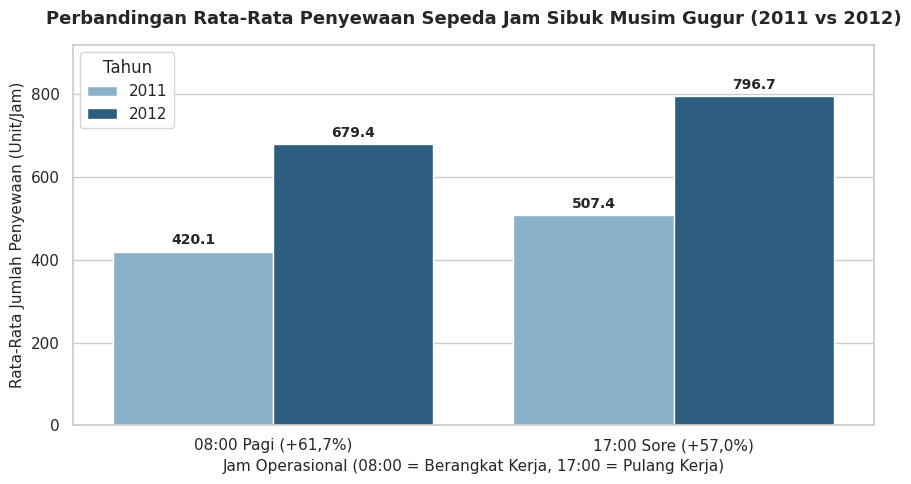

In [8]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=q1_summary,
    x="hr",
    y="mean",
    hue="year",
    palette=["#7FB3D5", "#1F618D"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=10, fontweight="bold")

plt.title("Perbandingan Rata-Rata Penyewaan Sepeda Jam Sibuk Musim Gugur (2011 vs 2012)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Jam Operasional (08:00 = Berangkat Kerja, 17:00 = Pulang Kerja)", fontsize=11)
plt.ylabel("Rata-Rata Jumlah Penyewaan (Unit/Jam)", fontsize=11)
plt.xticks(ticks=[0, 1], labels=["08:00 Pagi (+61,7%)", "17:00 Sore (+57,0%)"])
plt.ylim(0, 920)
plt.legend(title="Tahun")
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Variabel cuaca manakah (suhu udara, kelembaban, atau kecepatan angin) yang memiliki korelasi negatif terkuat terhadap penurunan jumlah penyewa kasual (casual) pada akhir pekan dan hari libur (workingday = 0) sepanjang periode 2011–2012 untuk merancang strategi promosi berbasis cuaca?


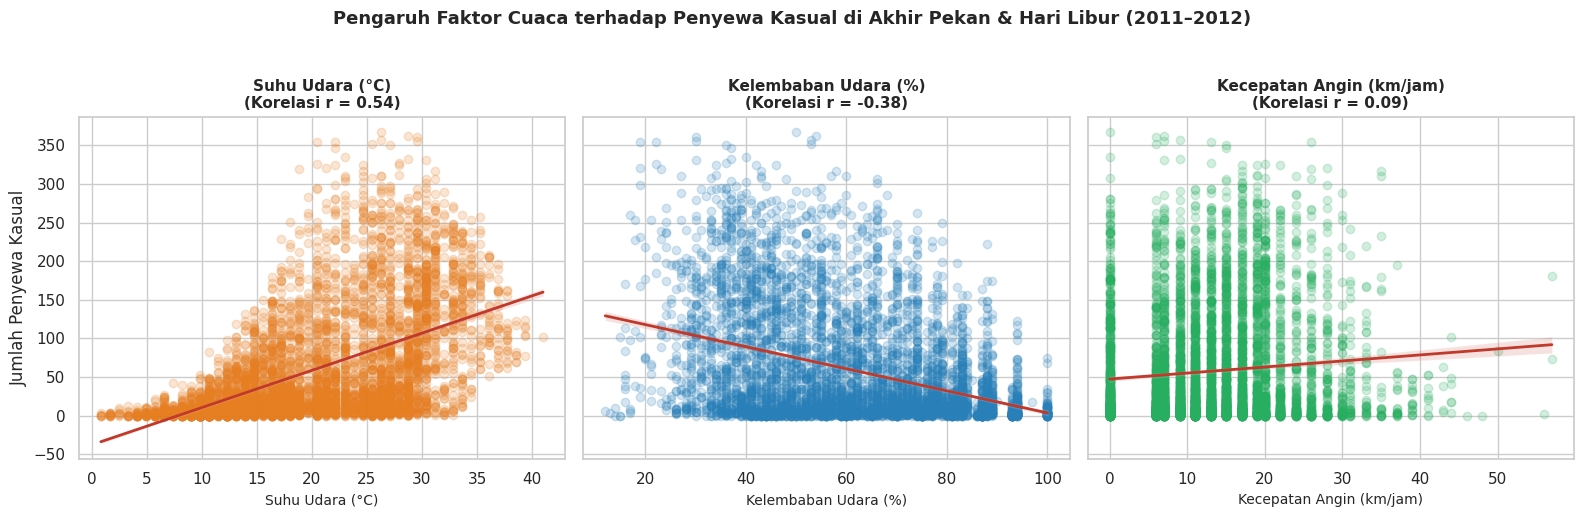

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

weather_vars = [
    ("temp_c", "Suhu Udara (°C)", "#E67E22"),
    ("hum_pct", "Kelembaban Udara (%)", "#2980B9"),
    ("windspeed_kmh", "Kecepatan Angin (km/jam)", "#27AE60")
]

for ax, (col, label, color) in zip(axes, weather_vars):
    sns.regplot(
        data=q2_df,
        x=col,
        y="casual",
        ax=ax,
        scatter_kws={"alpha": 0.2, "color": color},
        line_kws={"color": "#C0392B", "linewidth": 2}
    )
    corr_val = q2_df[col].corr(q2_df["casual"])
    ax.set_title(f"{label}\n(Korelasi r = {corr_val:.2f})", fontsize=11, fontweight="bold")
    ax.set_xlabel(label, fontsize=10)
    ax.set_ylabel("Jumlah Penyewa Kasual" if ax == axes[0] else "")

plt.suptitle("Pengaruh Faktor Cuaca terhadap Penyewa Kasual di Akhir Pekan & Hari Libur (2011–2012)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik batang pada Pertanyaan 1 memperlihatkan lonjakan kapasitas permintaan di atas 55% pada kedua jam sibuk musim gugur dari 2011 ke 2012, dengan beban puncak tertinggi berada pada pukul 17:00 (mendekati 800 unit/jam).
- Grafik regresi pada Pertanyaan 2 menegaskan bahwa garis tren kelembaban menurun tajam seiring meningkatnya persentase kelembaban, sementara garis tren kecepatan angin cenderung datar

## Analisis Lanjutan (Opsional)

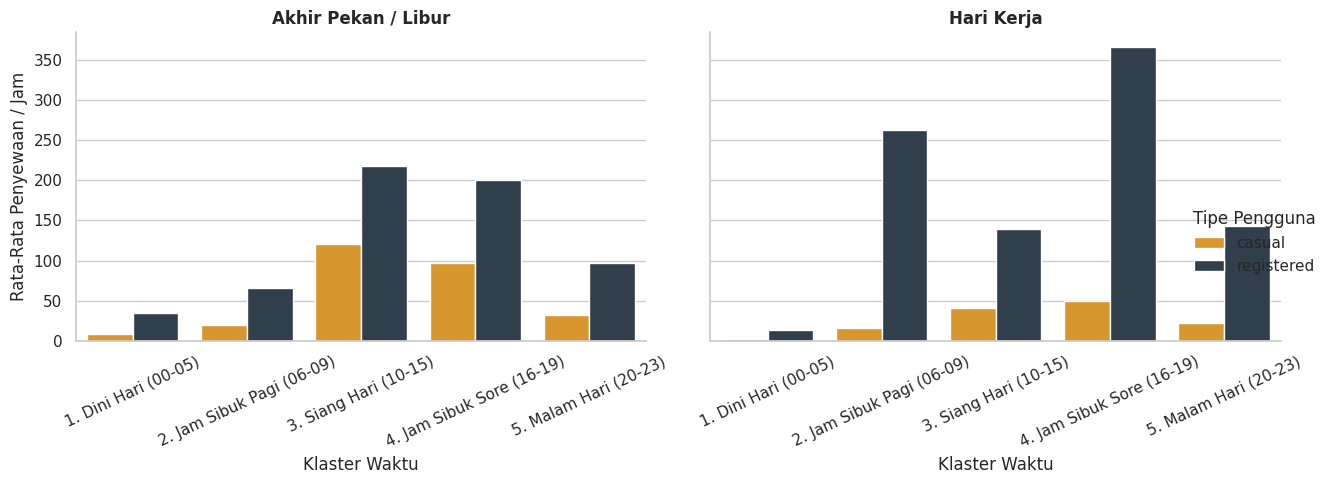

In [10]:
# Membuat klaster segmen waktu dalam sehari
def categorize_time(hr):
    if 0 <= hr <= 5:
        return "1. Dini Hari (00-05)"
    elif 6 <= hr <= 9:
        return "2. Jam Sibuk Pagi (06-09)"
    elif 10 <= hr <= 15:
        return "3. Siang Hari (10-15)"
    elif 16 <= hr <= 19:
        return "4. Jam Sibuk Sore (16-19)"
    else:
        return "5. Malam Hari (20-23)"

hour_df["time_cluster"] = hour_df["hr"].apply(categorize_time)
hour_df["day_type"] = hour_df["workingday"].map({0: "Akhir Pekan / Libur", 1: "Hari Kerja"})

cluster_agg = hour_df.groupby(["time_cluster", "day_type"])[["casual", "registered"]].mean().reset_index()
cluster_melted = cluster_agg.melt(
    id_vars=["time_cluster", "day_type"],
    value_vars=["casual", "registered"],
    var_name="Tipe Pengguna",
    value_name="Rata-Rata Penyewaan"
)

g = sns.catplot(
    data=cluster_melted,
    x="time_cluster",
    y="Rata-Rata Penyewaan",
    hue="Tipe Pengguna",
    col="day_type",
    kind="bar",
    height=5,
    aspect=1.2,
    palette=["#F39C12", "#2C3E50"]
)
g.set_titles("{col_name}", fontsize=12, fontweight="bold")
g.set_axis_labels("Klaster Waktu", "Rata-Rata Penyewaan / Jam")
g.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Hari Kerja: Didominasi oleh pengguna registered (komuter) yang memuncak pada Jam Sibuk Sore (16:00–19:00) dengan rata-rata 365,57 unit/jam dan Jam Sibuk Pagi (06:00–09:00) sebesar 262,14 unit/jam
- Akhir Pekan / Libur: Aktivitas berpindah ke Siang Hari (10:00–15:00) di mana penyewa casual melonjak hampir 3 kali lipat dibanding hari kerja (dari 40,83 menjadi 120,78 unit/jam)

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan sepeda pada jam sibuk musim gugur di hari kerja mengalami pertumbuhan sangat signifikan dari tahun 2011 ke 2012, yakni naik sebesar 61,72% pada pukul 08:00 (dari 420,11 menjadi 679,38 unit/jam) dan naik 57,00% pada pukul 17:00 (dari 507,42 menjadi 796,66 unit/jam)
- **Conclusion pertanyaan 2:** Kelembaban udara (hum_pct) merupakan variabel cuaca dengan korelasi negatif terkuat ($r = -0,38$) terhadap penurunan jumlah penyewa kasual di akhir pekan dan hari libur, jauh lebih berpengaruh dibandingkan kecepatan angin ($r = +0,09$). Sebaliknya, kenaikan suhu hangat hingga kisaran optimal justru mendorong minat penyewa kasual ($r = +0,54$)
- ...

**Rekomendasi Action Item:**
- Tingkatkan alokasi stok sepeda minimal 55%–60% pada stasiun dekat area perkantoran dan simpul transportasi sebelum pukul 07:30 dan 16:30 selama hari kerja, khususnya saat memasuki periode puncak musim gugur (Fall)
- Terapkan sistem notifikasi promo otomatis (dynamic discount) bagi pengguna kasual pada akhir pekan pukul 10:00–15:00 ketika prakiraan cuaca menunjukkan kelembaban tinggi (>75%) atau suhu sejuk